# 1. Import Required Libraries

The following Python libraries are used in this lab:

- NumPy: For numerical calculations and array operations.
- OpenCV: For image processing operations.
- Matplotlib: For displaying images and plotting histograms.

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

print("NumPy Version:", np.__version__)
print("OpenCV Version:", cv2.__version__)
print("Libraries imported successfully.")

NumPy Version: 2.4.6
OpenCV Version: 5.0.0
Libraries imported successfully.


# 2. Image Loading and Validation

Colour Image Shape: (1086, 1448, 3)
Image Data Type: uint8


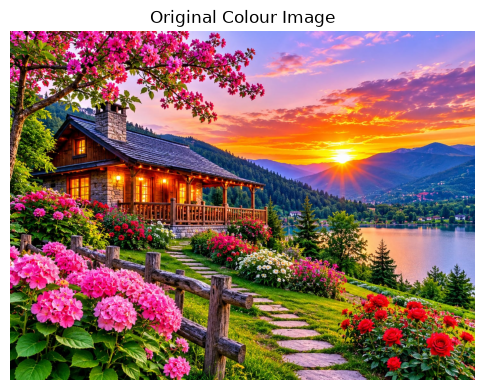

In [2]:
color_img = cv2.imread("img.jpeg")

if color_img is None:
    raise FileNotFoundError("Image not found. Check img.jpeg file.")

color_img = cv2.cvtColor(color_img, cv2.COLOR_BGR2RGB)

print("Colour Image Shape:", color_img.shape)
print("Image Data Type:", color_img.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(color_img)
plt.title("Original Colour Image")
plt.axis("off")
plt.show()

Image Shape: (1086, 1448)
Image Data Type: uint8
Minimum Intensity: 0
Maximum Intensity: 255


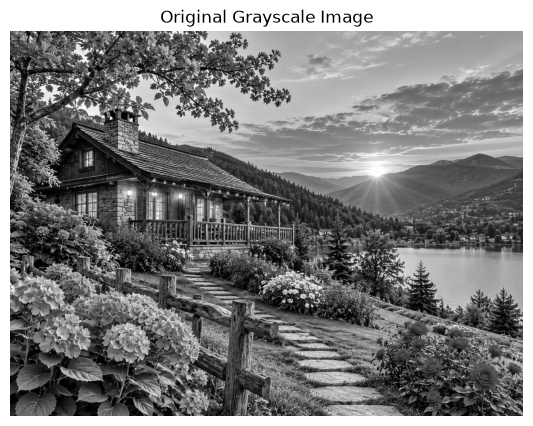

In [3]:
# Load image in grayscale
img = cv2.imread("img.jpeg", cv2.IMREAD_GRAYSCALE)

# Validate image
if img is None:
    raise FileNotFoundError("Image not found. Check the file name.")

if img.dtype != np.uint8:
    raise ValueError("Image must be 8-bit grayscale.")

# Keep original image unchanged
original = img.copy()

# Display image properties
print("Image Shape:", img.shape)
print("Image Data Type:", img.dtype)
print("Minimum Intensity:", img.min())
print("Maximum Intensity:", img.max())

# Display original image
plt.figure(figsize=(7, 5))
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

# 3. Task 1: Brightness Adjustment

In [4]:
# Dry run verification

pixels = np.array([30, 80, 128, 180, 240], dtype=np.int16)

# Brightness increase
bright_raw = pixels + 40
bright_result = np.clip(bright_raw, 0, 255).astype(np.uint8)

# Brightness decrease
dark_raw = pixels - 40
dark_result = np.clip(dark_raw, 0, 255).astype(np.uint8)

print("T1a Original Pixels:", pixels)
print("T1b Brightness +40 Raw:", bright_raw)
print("T1c Brightness +40 Final:", bright_result)
print("T1d Brightness -40 Raw:", dark_raw)
print("T1e Brightness -40 Final:", dark_result)

T1a Original Pixels: [ 30  80 128 180 240]
T1b Brightness +40 Raw: [ 70 120 168 220 280]
T1c Brightness +40 Final: [ 70 120 168 220 255]
T1d Brightness -40 Raw: [-10  40  88 140 200]
T1e Brightness -40 Final: [  0  40  88 140 200]


## 3.2 Brightness Adjustment Using NumPy


T1f: Brightness increase completed.
T1g: Brightness decrease completed.


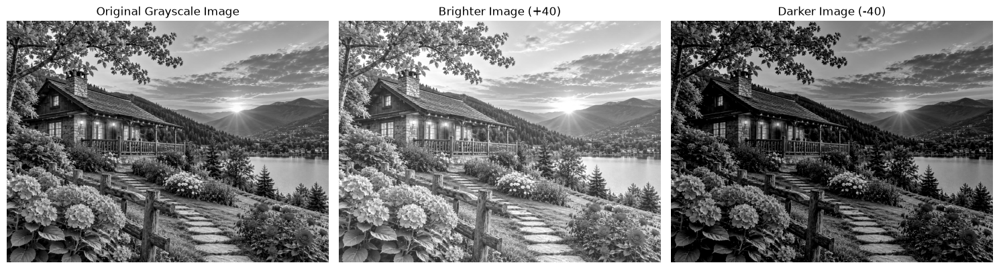

In [5]:
# Brightness adjustment using NumPy

img_int = original.astype(np.int16)

# Increase brightness
bright_img = np.clip(img_int + 40, 0, 255).astype(np.uint8)

# Decrease brightness
dark_img = np.clip(img_int - 40, 0, 255).astype(np.uint8)

print("T1f: Brightness increase completed.")
print("T1g: Brightness decrease completed.")

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(bright_img, cmap="gray", vmin=0, vmax=255)
plt.title("Brighter Image (+40)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(dark_img, cmap="gray", vmin=0, vmax=255)
plt.title("Darker Image (-40)")
plt.axis("off")

plt.tight_layout()
plt.show()

## 3.3 Brightness Adjustment Using Nested Loops


In [6]:
# Brightness increase using nested loops

loop_img = np.zeros_like(original)

for i in range(original.shape[0]):
    for j in range(original.shape[1]):
        value = int(original[i, j]) + 40
        loop_img[i, j] = np.clip(value, 0, 255)

# Verify both results
match = np.array_equal(loop_img, bright_img)

print("T1h: Nested loops brightness completed.")
print("T1i: NumPy and Nested Loops Match:", match)

T1h: Nested loops brightness completed.
T1i: NumPy and Nested Loops Match: True


# 4. Task 2: Linear Contrast from Zero

In [7]:
# Task 2: Dry run verification

pixels = np.array([30, 80, 128, 180, 240], dtype=np.int16)

raw_values = 1.5 * pixels
final_values = np.clip(raw_values, 0, 255).astype(np.uint8)

print("T2a Original Pixels:", pixels)
print("T2b Raw Values:", raw_values)
print("T2c Final Values:", final_values)
print("T2d Saturated Pixels:", np.sum(raw_values > 255))

T2a Original Pixels: [ 30  80 128 180 240]
T2b Raw Values: [ 45. 120. 192. 270. 360.]
T2c Final Values: [ 45 120 192 255 255]
T2d Saturated Pixels: 2


## 4.2 Linear Contrast Implementation


T2e: Linear contrast adjustment completed.


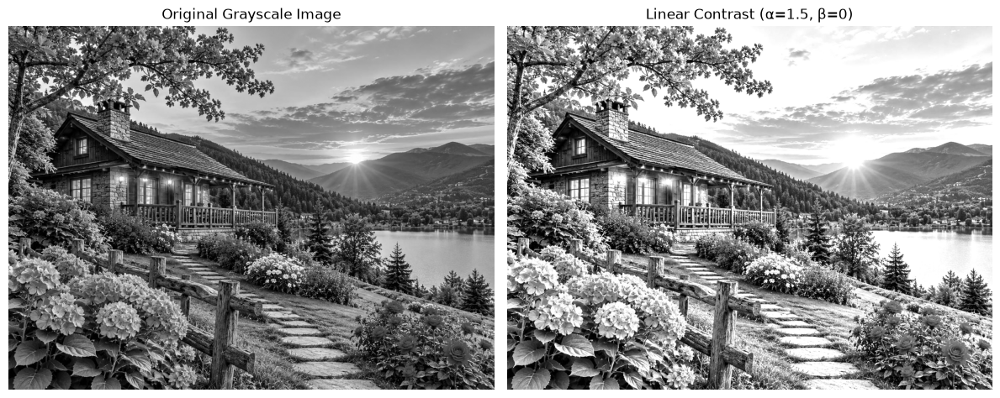

In [8]:
# Apply linear contrast from zero

contrast_zero = np.clip(
    original.astype(np.float32) * 1.5,
    0, 255
).astype(np.uint8)

print("T2e: Linear contrast adjustment completed.")

# Display comparison

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(contrast_zero, cmap="gray", vmin=0, vmax=255)
plt.title("Linear Contrast (α=1.5, β=0)")
plt.axis("off")

plt.tight_layout()
plt.show()

# 5. Task 3: Contrast Centered at 128


In [9]:
# Task 3: Dry run verification

pixels = np.array([30, 80, 128, 180, 240], dtype=np.int16)

# Contrast with alpha = 1.5
raw_15 = (pixels - 128) * 1.5 + 128
result_15 = np.clip(raw_15, 0, 255).astype(np.uint8)

# Contrast with alpha = 0.5
raw_05 = (pixels - 128) * 0.5 + 128
result_05 = np.clip(raw_05, 0, 255).astype(np.uint8)

print("T3a Original Pixels:", pixels)
print("T3b Alpha 1.5 Raw:", raw_15)
print("T3c Alpha 1.5 Final:", result_15)
print("T3d Alpha 0.5 Raw:", raw_05)
print("T3e Alpha 0.5 Final:", result_05)
print("T3f Pixel at 128:", result_15[2], result_05[2])

T3a Original Pixels: [ 30  80 128 180 240]
T3b Alpha 1.5 Raw: [-19.  56. 128. 206. 296.]
T3c Alpha 1.5 Final: [  0  56 128 206 255]
T3d Alpha 0.5 Raw: [ 79. 104. 128. 154. 184.]
T3e Alpha 0.5 Final: [ 79 104 128 154 184]
T3f Pixel at 128: 128 128


## 5.2 Contrast Adjustment Implementation

T3g: Contrast transformations completed.


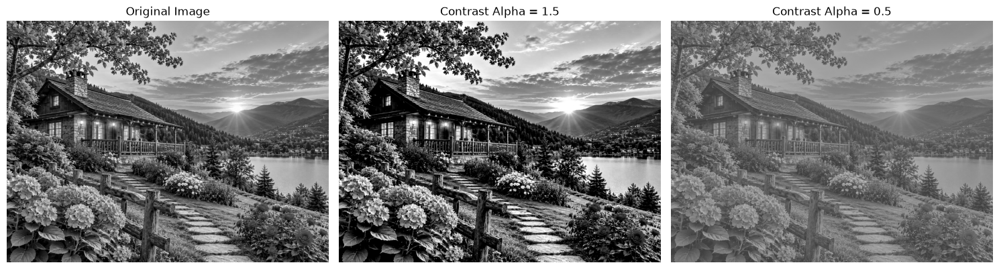

In [10]:
# Contrast centered at 128

img_float = original.astype(np.float32)

contrast_15 = np.clip(
    (img_float - 128) * 1.5 + 128,
    0, 255
).astype(np.uint8)

contrast_05 = np.clip(
    (img_float - 128) * 0.5 + 128,
    0, 255
).astype(np.uint8)

print("T3g: Contrast transformations completed.")

# Display comparison

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(contrast_15, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast Alpha = 1.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(contrast_05, cmap="gray", vmin=0, vmax=255)
plt.title("Contrast Alpha = 0.5")
plt.axis("off")

plt.tight_layout()
plt.show()

# 6. Task 4: Image Negative


In [11]:
# Task 4: Dry run verification

pixels = np.array([30, 80, 128, 180, 240], dtype=np.uint8)

# Apply negative transformation
negative_pixels = 255 - pixels

# Apply negative again
recovered_pixels = 255 - negative_pixels

print("T4a Original Pixels:", pixels)
print("T4b Negative Pixels:", negative_pixels)
print("T4c Recovered Pixels:", recovered_pixels)
print("T4d Original Recovered:", np.array_equal(pixels, recovered_pixels))

T4a Original Pixels: [ 30  80 128 180 240]
T4b Negative Pixels: [225 175 127  75  15]
T4c Recovered Pixels: [ 30  80 128 180 240]
T4d Original Recovered: True


## 6.2 Image Negative Implementation

T4e: Image negative transformation completed.
T4f: Original image recovered: True


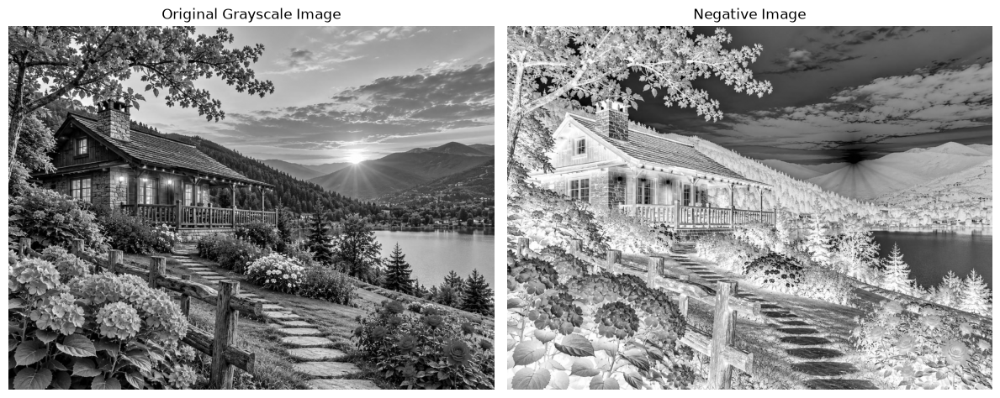

In [12]:
# Apply negative transformation to image

negative_img = 255 - original

print("T4e: Image negative transformation completed.")

# Apply negative again
recovered_img = 255 - negative_img

print("T4f: Original image recovered:",
      np.array_equal(original, recovered_img))

# Display comparison

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(negative_img, cmap="gray", vmin=0, vmax=255)
plt.title("Negative Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# 7. Task 5: Gamma Correction


In [13]:
# Task 5: Dry run verification

pixels = np.array([0, 64, 128, 192, 255], dtype=np.float64)

# Normalization
normalized = pixels / 255

# Gamma 0.5
power_05 = normalized ** 0.5
scaled_05 = 255 * power_05
result_05 = scaled_05.astype(np.uint8)

# Gamma 2.0
power_20 = normalized ** 2.0
scaled_20 = 255 * power_20
result_20 = scaled_20.astype(np.uint8)

print("T5a Original Pixels:", pixels.astype(np.uint8))
print("T5b Normalized Values:", normalized)
print("T5c Gamma 0.5 Power:", power_05)
print("T5d Gamma 0.5 Scaled:", scaled_05)
print("T5e Gamma 0.5 Final:", result_05)
print("T5f Gamma 2.0 Power:", power_20)
print("T5g Gamma 2.0 Scaled:", scaled_20)
print("T5h Gamma 2.0 Final:", result_20)

print("T5i Endpoints Fixed:",
      result_05[0] == 0 and result_05[-1] == 255
      and result_20[0] == 0 and result_20[-1] == 255)

T5a Original Pixels: [  0  64 128 192 255]
T5b Normalized Values: [0.         0.25098039 0.50196078 0.75294118 1.        ]
T5c Gamma 0.5 Power: [0.         0.50097943 0.70849191 0.86772183 1.        ]
T5d Gamma 0.5 Scaled: [  0.         127.74975538 180.66543665 221.26906698 255.        ]
T5e Gamma 0.5 Final: [  0 127 180 221 255]
T5f Gamma 2.0 Power: [0.         0.06299116 0.25196463 0.56692042 1.        ]
T5g Gamma 2.0 Scaled: [  0.          16.0627451   64.25098039 144.56470588 255.        ]
T5h Gamma 2.0 Final: [  0  16  64 144 255]
T5i Endpoints Fixed: True


## 7.2 Gamma Correction Implementation


T5j: Gamma correction completed.
T5k: Gamma 0.5 minimum and maximum: 0 255
T5l: Gamma 2.0 minimum and maximum: 0 255


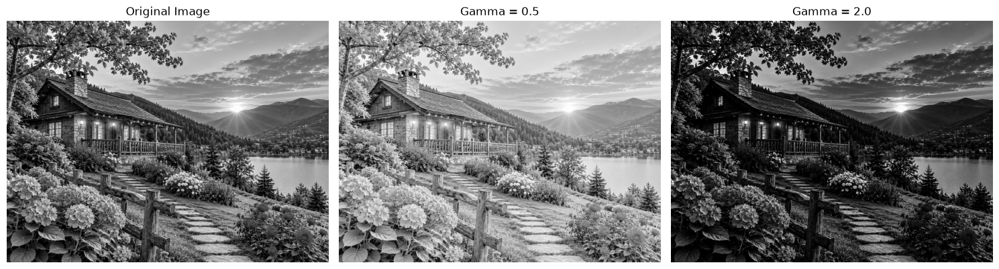

In [14]:
# Apply gamma correction to original image

img_normalized = original.astype(np.float64) / 255.0

# Gamma = 0.5
gamma_05 = (255 * (img_normalized ** 0.5)).astype(np.uint8)

# Gamma = 2.0
gamma_20 = (255 * (img_normalized ** 2.0)).astype(np.uint8)

print("T5j: Gamma correction completed.")
print("T5k: Gamma 0.5 minimum and maximum:",
      gamma_05.min(), gamma_05.max())
print("T5l: Gamma 2.0 minimum and maximum:",
      gamma_20.min(), gamma_20.max())

# Display comparison

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gamma_05, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 0.5")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gamma_20, cmap="gray", vmin=0, vmax=255)
plt.title("Gamma = 2.0")
plt.axis("off")

plt.tight_layout()
plt.show()

## Task 6: Grayscale Histogram


In [15]:
A = np.array([[0, 50, 50, 100],
              [100, 150, 200, 255]], dtype=np.uint8)

values, frequencies = np.unique(A, return_counts=True)

total_pixels = A.size
probabilities = frequencies / total_pixels

print("T6a: Intensity Values:", values)
print("T6b: Frequencies:", frequencies)
print("T6c: Total Pixels:", total_pixels)
print("T6d: Probabilities:", probabilities)
print("T6e: Sum of Frequencies:", frequencies.sum())
print("T6f: Sum of Probabilities:", probabilities.sum())

T6a: Intensity Values: [  0  50 100 150 200 255]
T6b: Frequencies: [1 2 2 1 1 1]
T6c: Total Pixels: 8
T6d: Probabilities: [0.125 0.25  0.25  0.125 0.125 0.125]
T6e: Sum of Frequencies: 8
T6f: Sum of Probabilities: 1.0


### Histogram of Original Grayscale Image

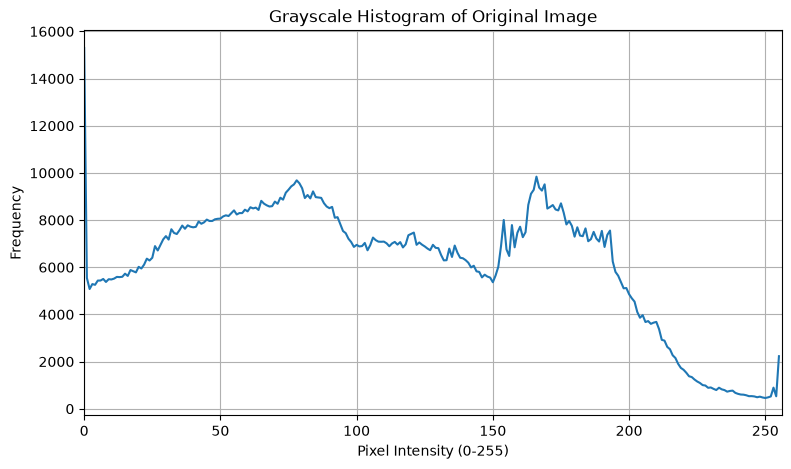

T6g: Histogram Shape: (256,)
T6h: Total Pixels: 1572528
T6i: Dark Pixels (0-84): 645368 = 41.04 %
T6j: Medium Pixels (85-169): 610509 = 38.82 %
T6k: Bright Pixels (170-255): 316651 = 20.14 %


In [16]:
hist = cv2.calcHist([original], [0], None, [256], [0, 256])

plt.figure(figsize=(9, 5))
plt.plot(hist)
plt.title("Grayscale Histogram of Original Image")
plt.xlabel("Pixel Intensity (0-255)")
plt.ylabel("Frequency")
plt.xlim(0, 256)
plt.grid(True)
plt.show()

print("T6g: Histogram Shape:", hist.shape)
print("T6h: Total Pixels:", int(hist.sum()))

dark = np.sum(original < 85)
medium = np.sum((original >= 85) & (original < 170))
bright = np.sum(original >= 170)

total = original.size

print("T6i: Dark Pixels (0-84):", dark, "=", round(dark / total * 100, 2), "%")
print("T6j: Medium Pixels (85-169):", medium, "=", round(medium / total * 100, 2), "%")
print("T6k: Bright Pixels (170-255):", bright, "=", round(bright / total * 100, 2), "%")

## Task 7: Global Histogram Equalization


T7a: Original Image Shape: (1086, 1448)
T7b: Equalized Image Shape: (1086, 1448)
T7c: Histogram Equalization completed successfully.


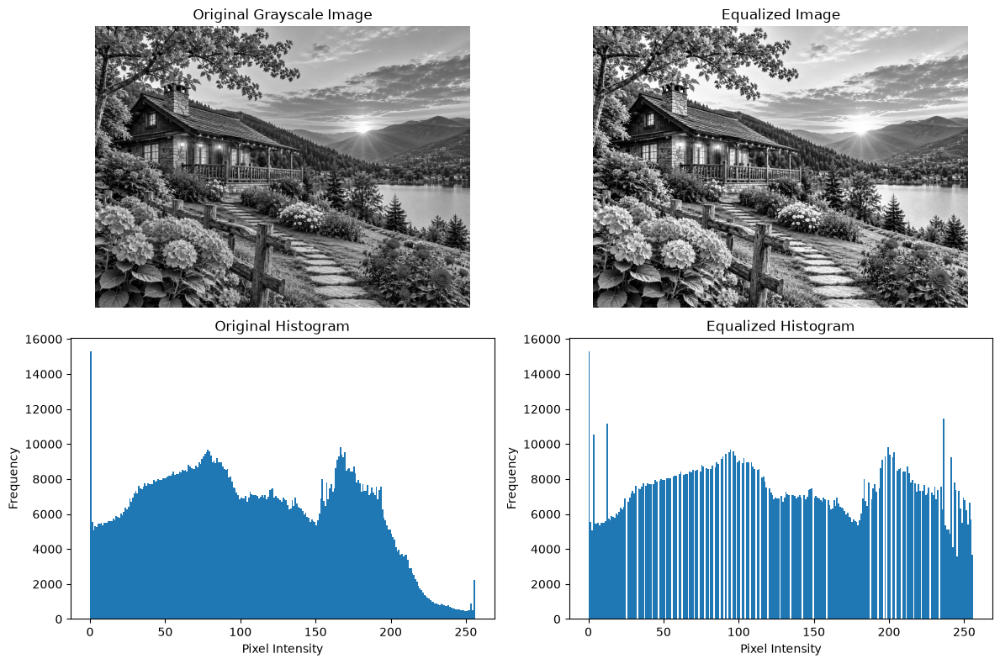

In [17]:
# Task 7: Global Histogram Equalization

equalized_img = cv2.equalizeHist(original)

print("T7a: Original Image Shape:", original.shape)
print("T7b: Equalized Image Shape:", equalized_img.shape)
print("T7c: Histogram Equalization completed successfully.")

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Equalized Image")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.hist(original.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.subplot(2, 2, 4)
plt.hist(equalized_img.ravel(), bins=256, range=(0, 256))
plt.title("Equalized Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Task 8: Contrast Limited Adaptive Histogram Equalization (CLAHE)


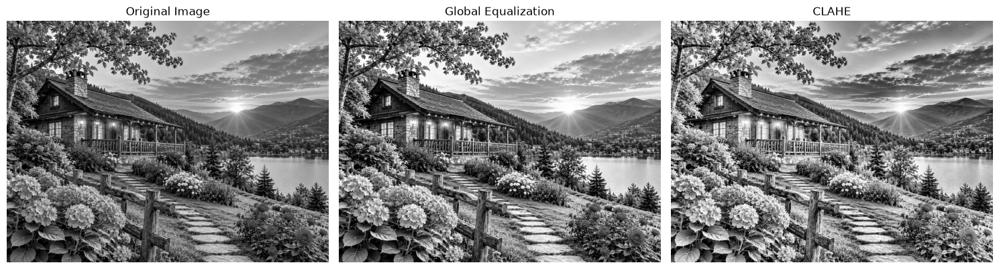

T8g: Original Shape: (1086, 1448)
T8h: CLAHE Shape: (1086, 1448)
T8i: CLAHE Data Type: uint8


In [18]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

clahe_img = clahe.apply(original)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(equalized_img, cmap="gray", vmin=0, vmax=255)
plt.title("Global Equalization")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(clahe_img, cmap="gray", vmin=0, vmax=255)
plt.title("CLAHE")
plt.axis("off")

plt.tight_layout()
plt.show()

print("T8g: Original Shape:", original.shape)
print("T8h: CLAHE Shape:", clahe_img.shape)
print("T8i: CLAHE Data Type:", clahe_img.dtype)

## Task 9: Fixed Binary Thresholding


In [3]:
# Task 9: Fixed Thresholding Dry Run

pixels = np.array([0, 80, 127, 128, 180, 255])

result_127 = np.where(pixels > 127, 255, 0)
result_180 = np.where(pixels > 180, 255, 0)

print("T9a: Input Pixels:", pixels)
print("T9b: Output at T=127:", result_127)
print("T9c: Output at T=180:", result_180)

print("T9d: White Pixels at T=127:", np.sum(result_127 == 255))
print("T9e: White Pixels at T=180:", np.sum(result_180 == 255))

print("T9f: Unique Values:", np.unique(result_127))

T9a: Input Pixels: [  0  80 127 128 180 255]
T9b: Output at T=127: [  0   0   0 255 255 255]
T9c: Output at T=180: [  0   0   0   0   0 255]
T9d: White Pixels at T=127: 3
T9e: White Pixels at T=180: 1
T9f: Unique Values: [  0 255]


T9a: Threshold 127 applied successfully.
T9b: Threshold 180 applied successfully.


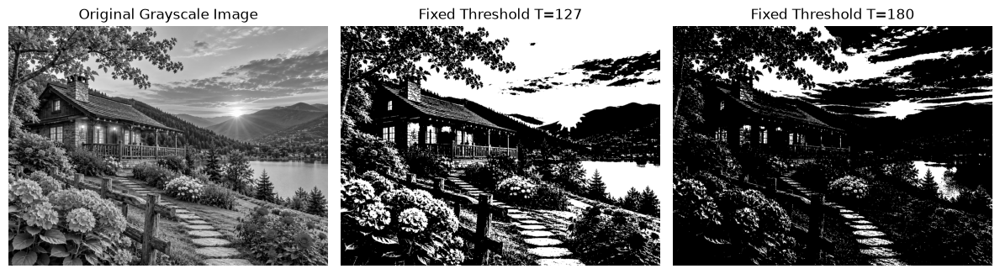

In [19]:
# Task 9: Fixed Thresholding

# Threshold value 127
_, binary_img = cv2.threshold(
    original, 127, 255, cv2.THRESH_BINARY
)

# Threshold value 180
_, binary_180 = cv2.threshold(
    original, 180, 255, cv2.THRESH_BINARY
)

print("T9a: Threshold 127 applied successfully.")
print("T9b: Threshold 180 applied successfully.")

plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold T=127")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(binary_180, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold T=180")
plt.axis("off")

plt.tight_layout()
plt.show()

## Task 10: Otsu's Thresholding

In [4]:
# Task 10: Otsu Thresholding Dry Run

pixels = np.array([0, 1, 4, 5], dtype=np.uint8)

def otsu_score(T):
    class0 = pixels[pixels <= T]
    class1 = pixels[pixels > T]

    if len(class0) == 0 or len(class1) == 0:
        return 0, 0, 0, 0

    w0 = len(class0) / len(pixels)
    w1 = len(class1) / len(pixels)

    mu0 = np.mean(class0)
    mu1 = np.mean(class1)

    score = w0 * w1 * (mu0 - mu1) ** 2

    return w0, w1, mu0, mu1, score


for T in range(5):
    values = otsu_score(T)
    print("T =", T, "Results:", values)

best_T = 1

print("T10a: Selected Threshold:", best_T)

otsu_result = np.where(pixels > best_T, 255, 0)

print("T10b: Predicted Mask:", otsu_result)

T = 0 Results: (0.25, 0.75, np.float64(0.0), np.float64(3.3333333333333335), np.float64(2.0833333333333335))
T = 1 Results: (0.5, 0.5, np.float64(0.5), np.float64(4.5), np.float64(4.0))
T = 2 Results: (0.5, 0.5, np.float64(0.5), np.float64(4.5), np.float64(4.0))
T = 3 Results: (0.5, 0.5, np.float64(0.5), np.float64(4.5), np.float64(4.0))
T = 4 Results: (0.75, 0.25, np.float64(1.6666666666666667), np.float64(5.0), np.float64(2.083333333333333))
T10a: Selected Threshold: 1
T10b: Predicted Mask: [  0   0 255 255]


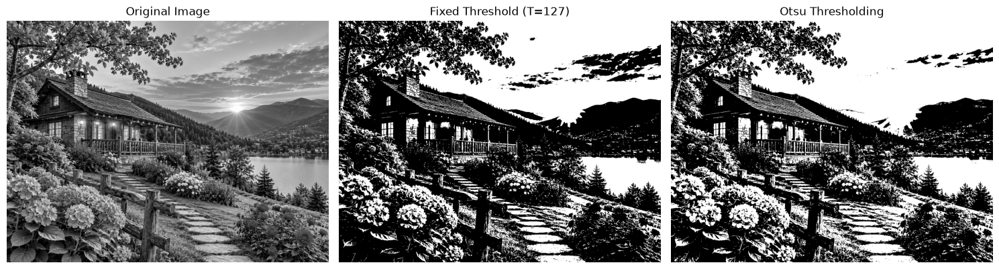

T10e: Otsu Threshold: 110.0
T10f: Otsu Unique Values: [  0 255]
T10g: Fixed Threshold: 127
T10h: Otsu White Pixels: 728682


In [20]:
otsu_threshold, otsu_img = cv2.threshold(
    original, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold (T=127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(otsu_img, cmap="gray", vmin=0, vmax=255)
plt.title("Otsu Thresholding")
plt.axis("off")

plt.tight_layout()
plt.show()

print("T10e: Otsu Threshold:", otsu_threshold)
print("T10f: Otsu Unique Values:", np.unique(otsu_img))
print("T10g: Fixed Threshold:", 127)
print("T10h: Otsu White Pixels:", np.sum(otsu_img == 255))

## Task 11: Adaptive Gaussian Thresholding


In [5]:
# Task 11: Adaptive Gaussian Thresholding Dry Run

neighborhood = np.array([
    [100, 100, 100],
    [100, 120, 140],
    [140, 140, 140]
], dtype=float)

weights = np.array([
    [1, 2, 1],
    [2, 4, 2],
    [1, 2, 1]
], dtype=float) / 16

weighted_mean = np.sum(neighborhood * weights)

C = 2
threshold = weighted_mean - C

center_pixel = 120
equal_pixel = threshold

print("T11a: Weighted Mean:", weighted_mean)
print("T11b: Threshold:", threshold)

print("T11c: Center Pixel Output:",
      255 if center_pixel > threshold else 0)

print("T11d: Equal Threshold Pixel Output:",
      255 if equal_pixel > threshold else 0)

T11a: Weighted Mean: 120.0
T11b: Threshold: 118.0
T11c: Center Pixel Output: 255
T11d: Equal Threshold Pixel Output: 0


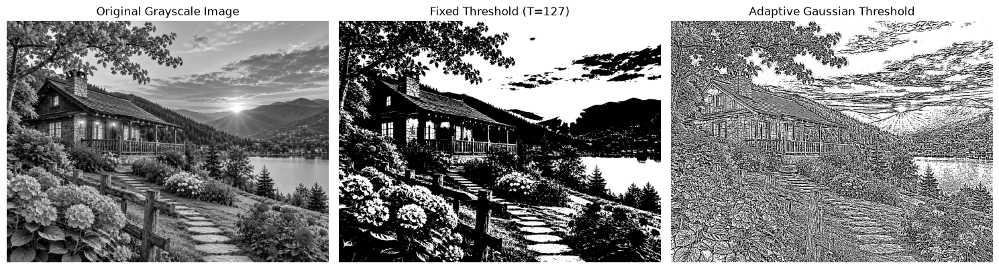

T11h: Original Shape: (1086, 1448)
T11i: Adaptive Image Shape: (1086, 1448)
T11j: Adaptive Unique Values: [  0 255]
T11k: Block Size: 11
T11l: Constant C: 2


In [21]:
adaptive_img = cv2.adaptiveThreshold(
    original,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original, cmap="gray", vmin=0, vmax=255)
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(binary_img, cmap="gray", vmin=0, vmax=255)
plt.title("Fixed Threshold (T=127)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(adaptive_img, cmap="gray", vmin=0, vmax=255)
plt.title("Adaptive Gaussian Threshold")
plt.axis("off")

plt.tight_layout()
plt.show()

print("T11h: Original Shape:", original.shape)
print("T11i: Adaptive Image Shape:", adaptive_img.shape)
print("T11j: Adaptive Unique Values:", np.unique(adaptive_img))
print("T11k: Block Size:", 11)
print("T11l: Constant C:", 2)

## Saving All Generated Images

In this section, all original and processed images are saved separately in PNG format for future use.

In [22]:
# Save All Generated Images

all_images = {
    "01_Original_Colour.png": cv2.cvtColor(color_img, cv2.COLOR_RGB2BGR),
    "02_Original_Grayscale.png": original,
    "03_Brightness_Plus_40.png": bright_img,
    "04_Brightness_Minus_40.png": dark_img,
    "05_Linear_Contrast.png": contrast_zero,
    "06_Centered_Contrast_1_5.png": contrast_15,
    "07_Centered_Contrast_0_5.png": contrast_05,
    "08_Negative.png": negative_img,
    "09_Gamma_0_5.png": gamma_05,
    "10_Gamma_2_0.png": gamma_20,
    "11_Global_Equalization.png": equalized_img,
    "12_CLAHE.png": clahe_img,
    "13_Fixed_Threshold.png": binary_img,
    "14_Otsu_Threshold.png": otsu_img,
    "15_Adaptive_Gaussian.png": adaptive_img
}

for filename, image in all_images.items():
    cv2.imwrite(filename, image)

print("All 15 images saved successfully!")
print("Total images saved:", len(all_images))

All 15 images saved successfully!
Total images saved: 15
